# Delhi's run lengths: a loading test already in SPARTAN's data (24 Nov 2026)

**Question (Ann, 24 Nov).** Is the HIPS compression a loading effect (how much is on the filter) or the air (composition on
polluted days)? At Addis the two cannot be told apart: the sampled volume is fixed (CV 1.5 %), so a dark filter is a dirty
day (`spartan_own_curve_design_20261124.ipynb`).

**Delhi changed how long it samples, at the same flow.** Every SPARTAN site runs at 5 L/min. Delhi went from 24 h of
sampling per filter (2022 to 2023) to 12 h (2024 to Oct 2025) to 6 h (from Nov 2025), each filter still spanning a 9am to
9am day: the sampler runs fewer hours inside the same day. That is the "vary duration, not flow" design of the proposed
paired experiment, between filters instead of within a pair.

**Test.** At a fixed concentration of a reference that does not depend on loading, does HIPS Fabs per unit of reference fall
when more air goes through the filter? With month fixed effects (so only filters from the same month are compared) and
standard errors clustered by month:

    log(Fabs / ref) = b_V · log(volume) + b_C · log(ref) + month

If HIPS reads low because of loading, b_V < 0; with the curve τ = x/(1 + x/τ∞) the expected b_V at optical depth τ is
−τ/τ∞ (about −0.24 at Delhi's median τ 0.54 with τ∞ 2.26). If the compression were only the air, b_V = 0.


In [1]:
import json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

ROOT = Path.cwd()
while not (ROOT / 'gallery').exists():
    ROOT = ROOT.parent
D = ROOT / 'gallery/app/public/data'
windows = json.load(open(D / 'weather/filters.json'))['windows']
ref = {r['id']: r for r in json.load(open(D / 'spartan_reference.json'))['rows']}
num = lambda v: v if isinstance(v, (int, float)) else np.nan
rows = []
for fid, w in windows.items():
    if not fid.startswith('INDH-'): continue
    r = ref.get(fid, {})
    if r.get('excluded'): continue
    fabs, V = num(r.get('HIPS Fabs')), num(r.get('Sampled volume'))
    if not (fabs > 0 and V > 0): continue
    rows.append(dict(id=fid, start=pd.Timestamp(w[0]), end=pd.Timestamp(w[1]), hours=w[2], V=V, fabs=fabs, tau=fabs * V / 353,
                     ec=num(r.get('EC (FTIR)')), pm=num(r.get('PM2.5 mass')), so4=num(r.get('Sulfate'))))
d = pd.DataFrame(rows).sort_values('start')
d['ym'] = d.start.dt.strftime('%Y-%m'); d['lv'] = np.log(d.V)
d['season'] = d.start.dt.month.map(lambda m: 'winter' if m in (11, 12, 1, 2) else 'pre-monsoon' if m in (3, 4, 5) else 'monsoon' if m in (6, 7, 8, 9) else 'post-monsoon')
print(len(d), 'Delhi filters with HIPS Fabs and volume;', d.ec.notna().sum(), 'with FTIR EC;', d.pm.notna().sum(), 'with PM2.5 mass')
print(d.groupby([d.start.dt.year, d.hours.round()]).size().rename('filters').to_string())
print('every window spans', sorted(set(((d.end - d.start) / pd.Timedelta(hours=1)).round())), 'h; sampled hours inside it:', sorted(d.hours.round().unique()))

138 Delhi filters with HIPS Fabs and volume; 109 with FTIR EC; 109 with PM2.5 mass
start  hours
2022   24.0      8
2023   24.0     21
2024   12.0     27
2025   6.0      16
       9.0       1
       11.0      1
       12.0     46
2026   6.0      18
every window spans [24.0] h; sampled hours inside it: [np.float64(6.0), np.float64(9.0), np.float64(11.0), np.float64(12.0), np.float64(24.0)]


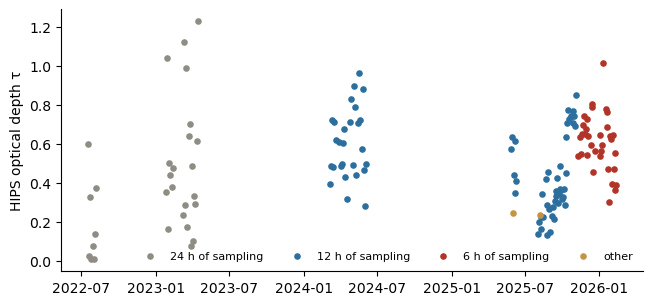

In [2]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
for h, c in ((24, '#8F8C84'), (12, '#2C6E9E'), (6, '#B23327')):
    x = d[d.hours.round() == h]; ax.scatter(x.start, x.tau, s=14, color=c, label=f'{h} h of sampling')
x = d[~d.hours.round().isin([6, 12, 24])]; ax.scatter(x.start, x.tau, s=14, color='#C49442', label='other')
ax.set_ylabel('HIPS optical depth τ'); ax.legend(frameon=False, fontsize=8, ncol=4); ax.spines[['top', 'right']].set_visible(False); plt.show()

The aethalometer (Kyan's Delhi hourly file, to June 2025) covers only 27 of these filters, nearly all 12 h, so it cannot
test run length. The references used are FTIR EC and gravimetric PM2.5 mass (and sulfate, noisier) from the same filters.

In [3]:
def fit(num_, den, data, form='lr ~ lc + lv + C(ym)'):
    x = data[(data[num_] > 0) & (data[den] > 0)].copy()
    x['lr'] = np.log(x[num_] / x[den]); x['lc'] = np.log(x[den])
    m = smf.ols(form, x).fit(cov_type='cluster', cov_kwds={'groups': pd.factorize(x.ym)[0]})
    return len(x), m.params['lv'], m.bse['lv'], m.params['lc'], m.bse['lc'], x.tau.median()

specs = [('month FE', 'lr ~ lc + lv + C(ym)', None), ('season + year FE', 'lr ~ lc + lv + C(season) + C(year)', None),
         ('2025 only, month FE', 'lr ~ lc + lv + C(ym)', lambda x: x[x.start.dt.year == 2025]),
         ('Aug 2025 on, month FE', 'lr ~ lc + lv + C(ym)', lambda x: x[x.start >= '2025-08-01'])]
d['year'] = d.start.dt.year
out = []
for num_, den, label in (('fabs', 'ec', 'HIPS Fabs / FTIR EC'), ('fabs', 'pm', 'HIPS Fabs / PM2.5 mass'), ('fabs', 'so4', 'HIPS Fabs / sulfate'),
                         ('ec', 'pm', 'placebo: FTIR EC / PM2.5'), ('so4', 'pm', 'placebo: sulfate / PM2.5')):
    for sname, form, sub in specs:
        n, b, se, bc, sec, tm = fit(num_, den, sub(d) if sub else d, form)
        out.append(dict(ratio=label, spec=sname, n=n, b_V=round(b, 3), se=round(se, 3), b_C=round(bc, 3), se_C=round(sec, 3),
                        expected=round(-tm / 2.2596, 3) if num_ == 'fabs' else 0.0))
tab = pd.DataFrame(out); print(tab.to_string(index=False))

                   ratio                  spec   n    b_V    se    b_C  se_C  expected
     HIPS Fabs / FTIR EC              month FE 108 -0.444 0.051 -0.360 0.067    -0.239
     HIPS Fabs / FTIR EC      season + year FE 108 -0.437 0.041 -0.357 0.071    -0.239
     HIPS Fabs / FTIR EC   2025 only, month FE  64 -0.436 0.062 -0.281 0.057    -0.200
     HIPS Fabs / FTIR EC Aug 2025 on, month FE  75 -0.455 0.064 -0.314 0.047    -0.238
  HIPS Fabs / PM2.5 mass              month FE 109 -0.280 0.051 -0.278 0.094    -0.238
  HIPS Fabs / PM2.5 mass      season + year FE 109 -0.233 0.062 -0.284 0.086    -0.238
  HIPS Fabs / PM2.5 mass   2025 only, month FE  64 -0.346 0.035 -0.347 0.120    -0.200
  HIPS Fabs / PM2.5 mass Aug 2025 on, month FE  75 -0.341 0.036 -0.326 0.114    -0.238
     HIPS Fabs / sulfate              month FE 109 -0.598 0.141 -0.831 0.099    -0.238
     HIPS Fabs / sulfate      season + year FE 109 -0.598 0.085 -0.827 0.076    -0.238
     HIPS Fabs / sulfate   2025 only, month

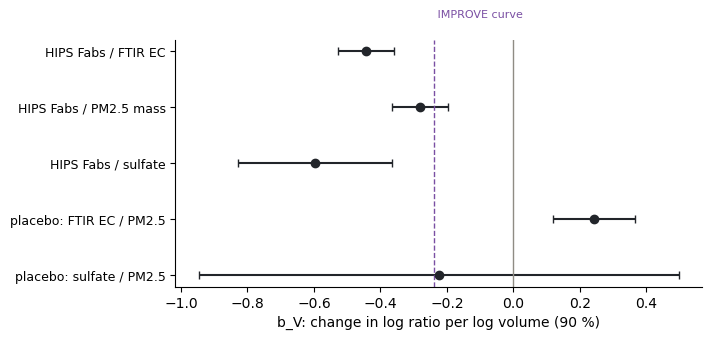

In [4]:
t = tab[tab.spec == 'month FE']
fig, ax = plt.subplots(figsize=(6.8, 3.2))
y = np.arange(len(t))[::-1]
ax.errorbar(t.b_V, y, xerr=1.645 * t.se, fmt='o', color='#22252A', capsize=3)
ax.axvline(0, color='#8F8C84', lw=1); ax.axvline(-0.54 / 2.2596, color='#7A4FA3', ls='--', lw=1)
ax.text(-0.54 / 2.2596, len(t) - 0.4, ' IMPROVE curve', color='#7A4FA3', fontsize=8)
ax.set_yticks(y); ax.set_yticklabels(t.ratio, fontsize=9); ax.set_xlabel('b_V: change in log ratio per log volume (90 %)')
ax.spines[['top', 'right']].set_visible(False); plt.show()

## What it says

- **HIPS reads lower per unit of reference when more air goes through the filter, in every specification.** Against PM2.5
  mass b_V is −0.23 to −0.35, against FTIR EC −0.44 to −0.46 (each about ±0.05). The IMPROVE curve predicts about −0.24 at
  Delhi's median optical depth. So there is a loading effect at SPARTAN, at least as strong as IMPROVE's curve implies.
- **It is not only the air.** These are filters from the same month at the same flow; what changes is the hours of sampling.
  A composition effect would need the 6 h and 12 h filters to sample different air, and they span the same 9am to 9am days.
- **The two references disagree by about 0.2, and the placebo shows why one of them moves.** FTIR EC per PM2.5 rises with
  volume (b_V +0.24 ± 0.08), which should be 0. Either FTIR EC reads relatively high on heavier filters, or the PM2.5 mass
  per volume is inflated on light filters (a fixed weighing or blank offset weighs more on a 6 h filter). The HIPS loading
  coefficient therefore sits between −0.28 (if FTIR is the one that moves) and −0.44 (if PM is). At Addis, FTIR EC is
  proportional to the self-calibrated aethalometer over a 5× range of loading, which favours FTIR being linear and the PM
  offset explaining the placebo, but that is a different site.
- **What it implies for the ceiling.** With b_V = −τ/τ∞ locally, −0.28 to −0.44 at τ 0.54 means τ∞ about 1.2 to 1.9: as
  strong a bend as IMPROVE's or stronger, the same direction as Addis (b 0.46 against 0.57 expected).

## Caveats

- Identification: with month fixed effects the comparison rests on the months with both run lengths (November 2025: nine
  6 h and two 12 h filters; August and June 2025 with 9 h and 11 h runs) plus small within-month volume differences. Season +
  year effects, which also use the 2025 switch, give the same answer. It is a strong hint, not the paired experiment.
- The sampler's duty cycle inside the day is assumed to spread the 6 and 12 h evenly over the 24 h window (every window is
  9am to 9am); if a 6 h run samples particular hours, composition could differ.
- Lots and HIPS batches are not controlled beyond month.

## Next

1. Settle the placebo: field blanks and the weighing offset for Delhi's 6 h filters (PM), and FTIR EC against the aethalometer
   at Delhi over 2024 to 2025 (Kyan's minute file) to check FTIR's linearity there.
2. The same test wherever a site changed run length or flow ratio at fixed flow (scan every site for within-month volume
   variation).
3. The paired experiment proper (`spartan_own_curve_design_20261124.ipynb`): Delhi shows SPARTAN can already duty-cycle within
   a day, so two slots at a 4× ratio over the same days is a configuration, not new hardware, if the SS5 can run two slots
   on one day.
